# Practical 6: Decision Tree Classifier

*Teacher-demo version.* Cells marked **ORIGINAL** are your repository notebook, unchanged. Cells marked **ADDED** are new: input experiments with real outputs, viva questions and common errors. Original file: `Basic_Decision_Tree_Classifier_Experiment.ipynb`

**A. Aim:** Train and visualize a decision tree classifier; analyze performance with/without pruning and depth control and demonstrate overfitting using synthetic data (make_moons).

**How to run (every practical)**

1. Install Python 3.10+ and Jupyter, then the libraries: `pip install numpy matplotlib scikit-learn jupyter`
2. Open a terminal / Anaconda Prompt in the folder containing this file and type `jupyter notebook`. Click this notebook.
3. Run cells one by one with **Shift + Enter** (or **Kernel -> Restart & Run All**). Run the cells in order - later cells need variables made by earlier ones.
4. To demonstrate a different result: edit the value on the line marked `# <-- CHANGED` in an experiment cell (or edit the same line in the original cell), then run that cell again. Run **Cell -> Run All** if later cells depend on it.
5. To print: **Ctrl + P** in the browser (as your lab readme suggests).

*Libraries needed here:* numpy, matplotlib, scikit-learn

---
## B / C. ORIGINAL PROGRAM AND ORIGINAL OUTPUT (unchanged cells follow)

<a href="https://colab.research.google.com/github/priyasathe123/ML-Practical-s/blob/main/Basic_Decision_Tree_Classifier_Experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment: Decision Tree Classifier

**Aim:** Train and visualize a decision tree classifier; analyze performance with/without pruning and depth control and demonstrate overfitting using synthetic data.

**Libraries:** NumPy, Matplotlib and Scikit-learn                                                                                                                    
Author: Dr. Priya B. Pandharbale

Run the following cells one by one.

## 1. Import libraries and create data

In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

# Create simple synthetic data
X, y = make_moons(n_samples=200, noise=0.25, random_state=42)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## 2. Display the dataset

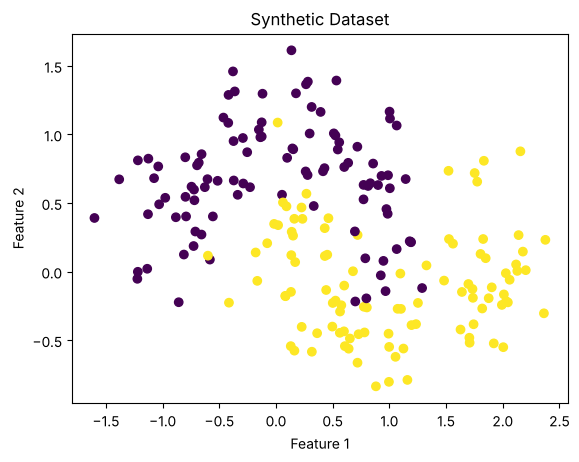

In [2]:
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Synthetic Dataset")
plt.show()

## 3. Decision Tree without pruning

Training Accuracy: 1.0
Testing Accuracy: 0.9


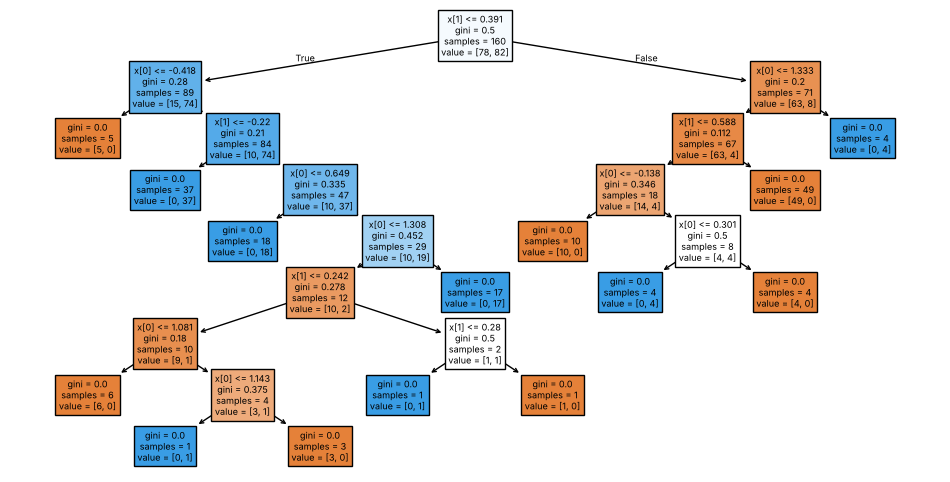

In [3]:
# Create and train the model
model1 = DecisionTreeClassifier(random_state=42)
model1.fit(X_train, y_train)

# Calculate accuracy
print("Training Accuracy:", accuracy_score(y_train, model1.predict(X_train)))
print("Testing Accuracy:", accuracy_score(y_test, model1.predict(X_test)))

# Display decision tree
plt.figure(figsize=(12, 6))
plot_tree(model1, filled=True)
plt.show()

**Observation:** A tree without depth control may become very large. It can learn the training data too closely. This is called overfitting.

## 4. Decision Tree with depth control

Training Accuracy: 0.9125
Testing Accuracy: 0.9


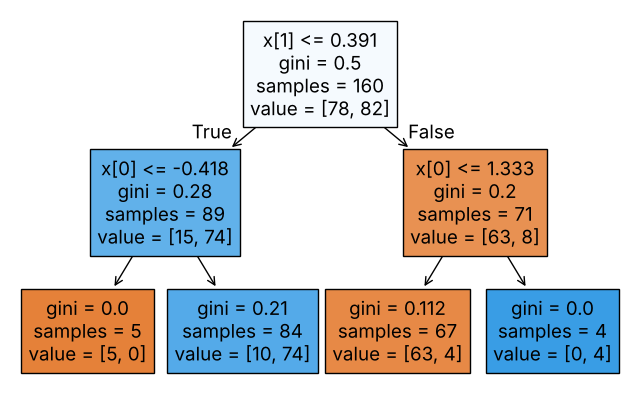

In [4]:
# Limit tree depth to 2
model2 = DecisionTreeClassifier(max_depth=2, random_state=42)
model2.fit(X_train, y_train)

print("Training Accuracy:", accuracy_score(y_train, model2.predict(X_train)))
print("Testing Accuracy:", accuracy_score(y_test, model2.predict(X_test)))

plt.figure(figsize=(8, 5))
plot_tree(model2, filled=True)
plt.show()

**Observation:** `max_depth=2` creates a smaller tree and helps control overfitting.

## 5. Decision Tree with pruning

Training Accuracy: 0.9875
Testing Accuracy: 0.9


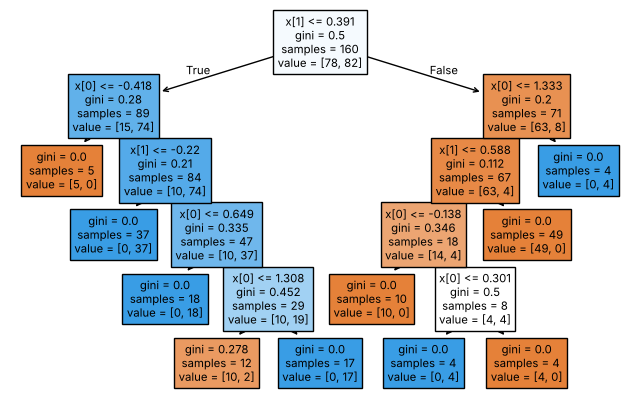

In [5]:
# Apply pruning
model3 = DecisionTreeClassifier(ccp_alpha=0.01, random_state=42)
model3.fit(X_train, y_train)

print("Training Accuracy:", accuracy_score(y_train, model3.predict(X_train)))
print("Testing Accuracy:", accuracy_score(y_test, model3.predict(X_test)))

plt.figure(figsize=(8, 5))
plot_tree(model3, filled=True)
plt.show()

**Observation:** Pruning removes some branches and makes the tree simpler.

## 6. Compare the three models

In [6]:
print("Model             Training Accuracy     Testing Accuracy")

print("Without pruning  ",
      round(accuracy_score(y_train, model1.predict(X_train)), 2), "              ",
      round(accuracy_score(y_test, model1.predict(X_test)), 2))

print("Depth control    ",
      round(accuracy_score(y_train, model2.predict(X_train)), 2), "              ",
      round(accuracy_score(y_test, model2.predict(X_test)), 2))

print("With pruning     ",
      round(accuracy_score(y_train, model3.predict(X_train)), 2), "              ",
      round(accuracy_score(y_test, model3.predict(X_test)), 2))

Model             Training Accuracy     Testing Accuracy
Without pruning   1.0                0.9
Depth control     0.91                0.9
With pruning      0.99                0.9


## Result

The Decision Tree Classifier was trained using synthetic data. The tree was visualized and its performance was compared without pruning, with depth control and with pruning. The difference between training and testing accuracy was used to understand overfitting.

---
## D / E / F. INPUT EXPERIMENTS (ADDED)
Each experiment cell is **self-contained** (it re-creates what it needs), so you can run any experiment on its own. Lines ending in `# <-- CHANGED (original: ...)` show exactly what was edited; `# ADDED line` marks new helper lines.

### D. Input Experiment 1 - More noisy data

**Changed input:** `noise=0.25` -> `0.5` in Step 1

**Where in the original notebook:** edit the line(s) shown as CHANGED in the original code cell #1 (section *1. Import libraries and create data*).

Training Accuracy: 1.0
Testing Accuracy: 0.7


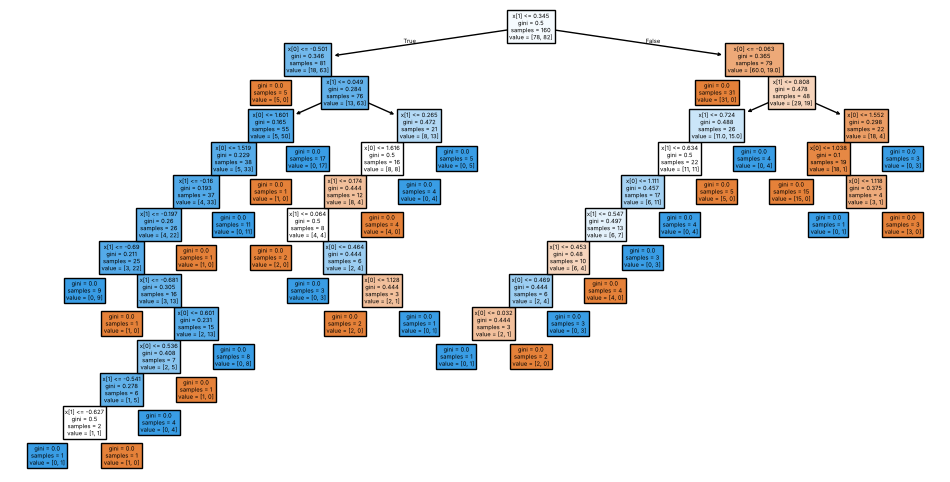

Training Accuracy: 0.8
Testing Accuracy: 0.675


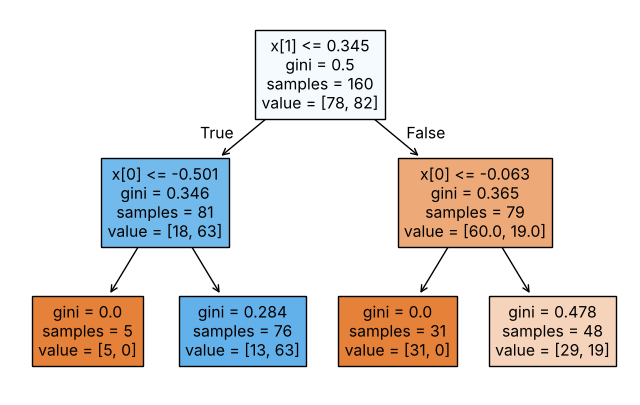

Training Accuracy: 0.925
Testing Accuracy: 0.75


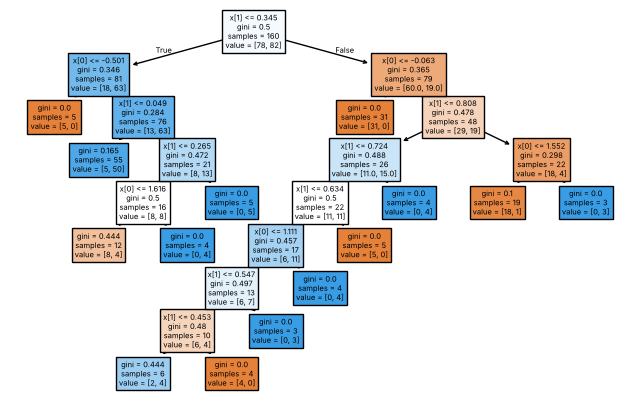

Model             Training Accuracy     Testing Accuracy
Without pruning   1.0                0.7
Depth control     0.8                0.68
With pruning      0.93                0.75


In [7]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

# Create simple synthetic data
X, y = make_moons(n_samples=200, noise=0.5, random_state=42)  # <-- CHANGED (original: X, y = make_moons(n_samples=200, noise=0.25, random_state=42))

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train the model
model1 = DecisionTreeClassifier(random_state=42)
model1.fit(X_train, y_train)

# Calculate accuracy
print("Training Accuracy:", accuracy_score(y_train, model1.predict(X_train)))
print("Testing Accuracy:", accuracy_score(y_test, model1.predict(X_test)))

# Display decision tree
plt.figure(figsize=(12, 6))
plot_tree(model1, filled=True)
plt.show()

# Limit tree depth to 2
model2 = DecisionTreeClassifier(max_depth=2, random_state=42)
model2.fit(X_train, y_train)

print("Training Accuracy:", accuracy_score(y_train, model2.predict(X_train)))
print("Testing Accuracy:", accuracy_score(y_test, model2.predict(X_test)))

plt.figure(figsize=(8, 5))
plot_tree(model2, filled=True)
plt.show()

# Apply pruning
model3 = DecisionTreeClassifier(ccp_alpha=0.01, random_state=42)
model3.fit(X_train, y_train)

print("Training Accuracy:", accuracy_score(y_train, model3.predict(X_train)))
print("Testing Accuracy:", accuracy_score(y_test, model3.predict(X_test)))

plt.figure(figsize=(8, 5))
plot_tree(model3, filled=True)
plt.show()

print("Model             Training Accuracy     Testing Accuracy")

print("Without pruning  ",
      round(accuracy_score(y_train, model1.predict(X_train)), 2), "              ",
      round(accuracy_score(y_test, model1.predict(X_test)), 2))

print("Depth control    ",
      round(accuracy_score(y_train, model2.predict(X_train)), 2), "              ",
      round(accuracy_score(y_test, model2.predict(X_test)), 2))

print("With pruning     ",
      round(accuracy_score(y_train, model3.predict(X_train)), 2), "              ",
      round(accuracy_score(y_test, model3.predict(X_test)), 2))

**Actual output explained**

**What changed:** `noise = 0.5` (was 0.25). Unpruned tree: training **1.0**, testing **0.70** (original 1.0 / 0.90). Depth 2: 0.80 / 0.675. Pruned (`ccp_alpha=0.01`): 0.925 / 0.75.

**Why:** with noisier data the classes overlap, so the unpruned tree memorises noise: perfect on training data but only 70 % on new data - a gap of 30 points, i.e. strong **overfitting**. The pruned tree has a smaller gap and the best test accuracy of the three. (The comparison table prints 0.68 for 0.675 because of `round(..., 2)`.)

### E. Input Experiment 2 - Very shallow tree (a decision stump)

**Changed input:** `max_depth=2` -> `1` in Step 4

**Where in the original notebook:** edit the line(s) shown as CHANGED in the original code cell #4 (section *4. Decision Tree with depth control*).

Training Accuracy: 0.85625
Testing Accuracy: 0.8


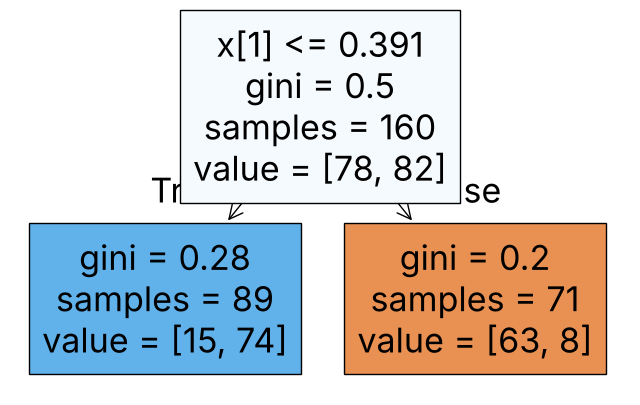

In [8]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

# Create simple synthetic data
X, y = make_moons(n_samples=200, noise=0.25, random_state=42)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Limit tree depth to 2
model2 = DecisionTreeClassifier(max_depth=1, random_state=42)  # <-- CHANGED (original: model2 = DecisionTreeClassifier(max_depth=2, random_state=42))
model2.fit(X_train, y_train)

print("Training Accuracy:", accuracy_score(y_train, model2.predict(X_train)))
print("Testing Accuracy:", accuracy_score(y_test, model2.predict(X_test)))

plt.figure(figsize=(8, 5))
plot_tree(model2, filled=True)
plt.show()

**Actual output explained**

**What changed:** `max_depth = 1` (a single split, a 'stump'). Training accuracy **0.85625**, testing **0.8** (the depth-2 original had 0.9125 / 0.9).

**Why:** one split can only draw one straight cut through the two moons, so the tree is too simple: **underfitting** - low accuracy on both training and test data. Opposite problem to the unpruned tree.

### F. Input Experiment 3 - Stronger pruning

**Changed input:** `ccp_alpha=0.01` -> `0.02` in Step 5

**Where in the original notebook:** edit the line(s) shown as CHANGED in the original code cell #5 (section *5. Decision Tree with pruning*).

Training Accuracy: 0.9625
Testing Accuracy: 0.925


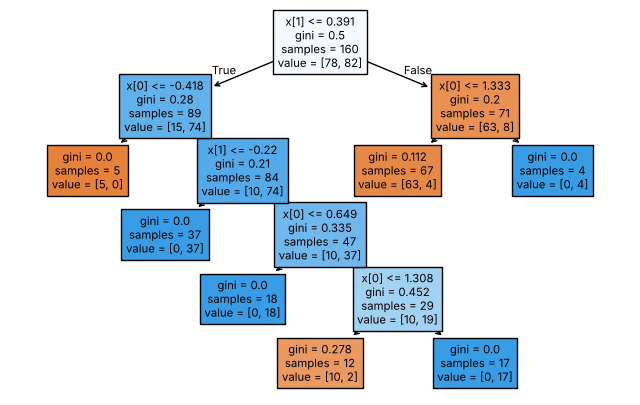

In [9]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

# Create simple synthetic data
X, y = make_moons(n_samples=200, noise=0.25, random_state=42)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Apply pruning
model3 = DecisionTreeClassifier(ccp_alpha=0.02, random_state=42)  # <-- CHANGED (original: model3 = DecisionTreeClassifier(ccp_alpha=0.01, random_state=42))
model3.fit(X_train, y_train)

print("Training Accuracy:", accuracy_score(y_train, model3.predict(X_train)))
print("Testing Accuracy:", accuracy_score(y_test, model3.predict(X_test)))

plt.figure(figsize=(8, 5))
plot_tree(model3, filled=True)
plt.show()

**Actual output explained**

**What changed:** `ccp_alpha = 0.02` (was 0.01). Training **0.9625**, testing **0.925** - the test accuracy is now *higher* than the unpruned tree's 0.90.

**Why:** a bigger alpha removes more weak branches (the tree shrinks from 14 leaves unpruned to 10 at alpha 0.01 and 7 at alpha 0.02), so it generalises better. But pruning too much hurts: in a check with `ccp_alpha=0.05` the tree collapses to 2 leaves and gives only 0.856 / 0.8.

---
## G. IMPORTANT VIVA QUESTIONS AND ANSWERS (ADDED)

**Q1. What criterion does DecisionTreeClassifier use by default?**  
Gini impurity (`criterion='gini'`); entropy/information gain is the alternative.

**Q2. What is overfitting and how is it shown in this practical?**  
The model fits training data (accuracy 1.0) but does worse on unseen data (0.9, or 0.7 with more noise). A large gap between training and testing accuracy indicates overfitting.

**Q3. Difference between pre-pruning and post-pruning?**  
Pre-pruning stops growth early (e.g. `max_depth`, `min_samples_leaf`). Post-pruning grows the full tree and removes branches afterwards - `ccp_alpha` implements cost-complexity pruning.

**Q4. What does `ccp_alpha` do?**  
It sets the penalty per leaf; a larger value removes more branches. In this data the number of leaves is 14 (alpha 0), 10 (0.01), 7 (0.02), 2 (0.05).

**Q5. Why does `max_depth=1` underfit?**  
One split gives only two regions; the moon-shaped classes need more flexible boundaries.

**Q6. Advantages and disadvantages of decision trees?**  
Easy to interpret and need no scaling, but unstable and prone to overfitting; ensembles such as random forests reduce variance.

**Q7. What is `make_moons`?**  
A synthetic dataset of two interleaving half circles; `noise` controls how much they overlap. It is non-linearly separable.

---
## Common errors and solutions (ADDED)

- `plot_tree` figure is tiny/unreadable -> increase `figsize`, or add `max_depth=3` inside `plot_tree(...)` to show only the top levels.
- `ImportError: plot_tree` -> scikit-learn older than 0.21; upgrade.
- Accuracy values differ from this guide -> you changed `random_state` or `test_size`.